In [3]:
# ============================================================================
# CELL 1: Kaggle GPU Check, Reproducibility Seeds & Input File Check
# ============================================================================
import os
import random
import urllib.request
import warnings
import numpy as np
import pandas as pd
import torch
import transformers
import datasets
import sklearn

warnings.filterwarnings("ignore")

# 1. Set global random seed for 100% reproducibility
SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)
os.environ["WANDB_DISABLED"] = "true"

# 2. Verify GPU hardware and library versions
print("=" * 65)
print("KAGGLE ENVIRONMENT & GPU CHECK")
print("=" * 65)
print(f"PyTorch Version      : {torch.__version__}")
print(f"Transformers Version : {transformers.__version__}")
print(f"CUDA GPU Available   : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)
        print(f"  -> GPU {i}: {torch.cuda.get_device_name(i)} ({props.total_memory / (1024**3):.2f} GB VRAM)")
else:
    print("WARNING: No GPU detected! Please turn on GPU T4 x2 in Settings -> Accelerator.")

# 3. Locate uploaded dataset files in /kaggle/input
print("\n" + "=" * 65)
print("FILES DETECTED IN /kaggle/input")
print("=" * 65)
found_files = []
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        full_path = os.path.join(root, file)
        found_files.append(full_path)
        print(f"  [FILE] {full_path}")

KAGGLE ENVIRONMENT & GPU CHECK
PyTorch Version      : 2.11.0+cu130
Transformers Version : 5.20.2
CUDA GPU Available   : True
  -> GPU 0: Tesla T4 (14.56 GB VRAM)
  -> GPU 1: Tesla T4 (14.56 GB VRAM)

FILES DETECTED IN /kaggle/input


Files found in /kaggle/input: ['/kaggle/input/datasets/richasingh3137/hindi-test-data/hindi_youtube_test_data.csv', '/kaggle/input/datasets/richasingh3137/semeval2016-task6-trainingdata-txt/semeval2016-task6-trainingdata.txt']

1. FULL SEMEVAL-2016 DATASET LOADED (ALL 2,814 ROWS)
File Path       : /kaggle/input/datasets/richasingh3137/semeval2016-task6-trainingdata-txt/semeval2016-task6-trainingdata.txt
Total Rows      : 2814
Columns         : ['ID', 'Target', 'Tweet', 'Stance']
Missing Values  : {'ID': 0, 'Target': 0, 'Tweet': 0, 'Stance': 0}

--- Cross-Tabulation of All Targets vs. Stance Labels ---
Stance                            AGAINST  FAVOR  NONE   All
Target                                                      
Atheism                               304     92   117   513
Climate Change is a Real Concern       15    212   168   395
Feminist Movement                     328    210   126   664
Hillary Clinton                       361    112   166   639
Legalization of Abortion 

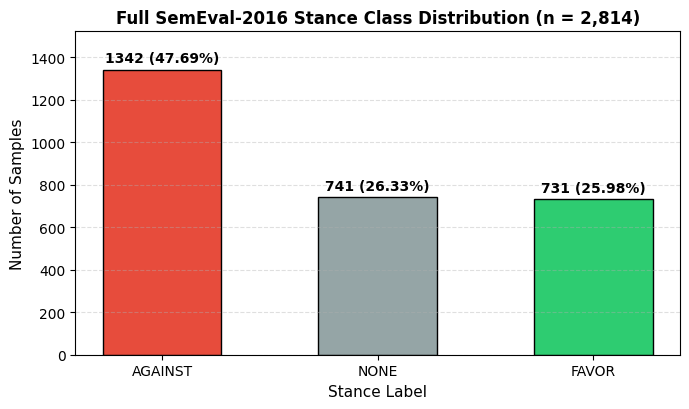

In [10]:
# ============================================================================
# CELL 2: Load the ENTIRE SemEval-2016 Dataset (All 2,814 Rows)
# ============================================================================
import os
import pandas as pd
import matplotlib.pyplot as plt

# 1. Scan /kaggle/input directly for semeval2016-task6-trainingdata.txt
found_files = []
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        found_files.append(os.path.join(root, file))

print("Files found in /kaggle/input:", found_files)

semeval_candidates = [f for f in found_files if "semeval" in f.lower() or f.lower().endswith(".txt")]
if len(semeval_candidates) == 0:
    raise FileNotFoundError(
        "No .txt file found in /kaggle/input! Please check the right-hand sidebar under 'Input' "
        "to make sure your uploaded dataset is attached to this notebook."
    )

DATA_PATH = semeval_candidates[0]

# Read tab-separated file using cp1252 encoding
full_df = pd.read_csv(DATA_PATH, sep="\t", encoding="cp1252")

print("\n" + "=" * 65)
print("1. FULL SEMEVAL-2016 DATASET LOADED (ALL 2,814 ROWS)")
print("=" * 65)
print(f"File Path       : {DATA_PATH}")
print(f"Total Rows      : {len(full_df)}")
print(f"Columns         : {list(full_df.columns)}")
print(f"Missing Values  : {full_df.isnull().sum().to_dict()}")

print("\n--- Cross-Tabulation of All Targets vs. Stance Labels ---")
print(pd.crosstab(full_df["Target"], full_df["Stance"], margins=True).to_string())

# 2. Keep ALL 2,814 rows so the models learn from all AGAINST (1,342), NONE (741), and FAVOR (731) examples!
dataset_df = full_df.copy().reset_index(drop=True)

stance_counts = dataset_df["Stance"].value_counts()
stance_pcts = (stance_counts / len(dataset_df) * 100).round(2)
summary_df = pd.DataFrame({
    "Count": stance_counts,
    "Percentage (%)": stance_pcts
})
print("\n--- Full Dataset Class Distribution (n = 2,814) ---")
print(summary_df.to_string())

# 3. Plot Full Class Distribution Chart
plt.figure(figsize=(7, 4.2))
colors = ["#e74c3c", "#95a5a6", "#2ecc71"]
bars = plt.bar(summary_df.index, summary_df["Count"], color=colors, edgecolor="black", width=0.55)

for bar, pct in zip(bars, summary_df["Percentage (%)"]):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 20,
        f"{int(height)} ({pct}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Full SemEval-2016 Stance Class Distribution (n = 2,814)", fontsize=12, fontweight="bold")
plt.xlabel("Stance Label", fontsize=11)
plt.ylabel("Number of Samples", fontsize=11)
plt.ylim(0, max(summary_df["Count"]) + 180)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("/kaggle/working/class_distribution_full.png", dpi=300)
plt.show()

In [11]:
# ============================================================================
# CELL 3: Text Cleaning, Label Mapping, Stratified Split & Class Weights (n=2,814)
# ============================================================================
import re
import html
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 42

# 1. Universal text cleaning function (supports both English & Hindi/Devanagari)
def clean_social_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = html.unescape(text)
    text = re.sub(r"#SemST\b", "", text, flags=re.IGNORECASE)
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"\bRT\s+@\w+:?", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

dataset_df["clean_text"] = dataset_df["Tweet"].apply(clean_social_text)

# 2. Define 3-class label mappings
LABEL2ID = {"AGAINST": 0, "NONE": 1, "FAVOR": 2}
ID2LABEL = {0: "AGAINST", 1: "NONE", 2: "FAVOR"}
CLASS_NAMES = ["AGAINST", "NONE", "FAVOR"]

dataset_df["label"] = dataset_df["Stance"].map(LABEL2ID)

# 3. Stratified 80/20 Train-Validation Split across ALL 2,814 rows
train_df, val_df = train_test_split(
    dataset_df,
    test_size=0.20,
    random_state=SEED,
    stratify=dataset_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

overlap_ids = set(train_df["ID"]).intersection(set(val_df["ID"]))
assert len(overlap_ids) == 0, f"DATA LEAKAGE DETECTED: {overlap_ids}"

print("=" * 65)
print("STRATIFIED TRAIN-VALIDATION SPLIT ON FULL DATASET (n = 2,814)")
print("=" * 65)
print(f"Training Set Size   : {len(train_df)} rows (80%)")
print(f"Validation Set Size : {len(val_df)} rows (20%)")
print(f"Overlapping IDs     : {len(overlap_ids)} (Zero Data Leakage Verified!)")

split_summary = pd.DataFrame({
    "Train Count": train_df["Stance"].value_counts(),
    "Train (%)": (train_df["Stance"].value_counts(normalize=True) * 100).round(2),
    "Val Count": val_df["Stance"].value_counts(),
    "Val (%)": (val_df["Stance"].value_counts(normalize=True) * 100).round(2),
}).loc[CLASS_NAMES]

print("\n--- Stratified Class Distribution (Full Dataset) ---")
print(split_summary.to_string())

# 4. Compute Balanced Class Weights on Training Set ONLY
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_df["label"].values
)
class_weights_tensor = torch.tensor(class_weights_np, dtype=torch.float)

print("\n" + "=" * 65)
print("BALANCED CLASS WEIGHTS FOR CROSS-ENTROPY LOSS")
print("=" * 65)
for cls_id, cls_name in ID2LABEL.items():
    print(f"  Class {cls_id} ({cls_name:7s}) -> Weight = {class_weights_np[cls_id]:.4f}")

STRATIFIED TRAIN-VALIDATION SPLIT ON FULL DATASET (n = 2,814)
Training Set Size   : 2251 rows (80%)
Validation Set Size : 563 rows (20%)
Overlapping IDs     : 0 (Zero Data Leakage Verified!)

--- Stratified Class Distribution (Full Dataset) ---
         Train Count  Train (%)  Val Count  Val (%)
Stance                                             
AGAINST         1073      47.67        269    47.78
NONE             593      26.34        148    26.29
FAVOR            585      25.99        146    25.93

BALANCED CLASS WEIGHTS FOR CROSS-ENTROPY LOSS
  Class 0 (AGAINST) -> Weight = 0.6993
  Class 1 (NONE   ) -> Weight = 1.2653
  Class 2 (FAVOR  ) -> Weight = 1.2826


In [12]:
# ============================================================================
# CELL 4: Shared Trainer, Evaluation & Hugging Face Checkpoint Saver
# ============================================================================
import gc
import time
import inspect
import seaborn as sns
import matplotlib.pyplot as plt
from torch import nn
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

MODEL_RESULTS = {}
SAVED_MODEL_PATHS = {}

# Optimized Hyperparameters for the full 2,814-row dataset
# Optimized Hyperparameters in Cell 4 for Maximum Accuracy & Macro F1 on Full Dataset
HYPERPARAMS = {
    "max_length": 96,
    "batch_size": 16,
    "learning_rate": 3e-5,
    "weight_decay": 0.01,
    "num_epochs": 8,
    "warmup_steps": 80,
    "early_stopping_patience": 3,
    "seed": SEED,
}

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc = accuracy_score(labels, preds)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(labels, preds, average="weighted", zero_division=0)
    per_class_p, per_class_r, per_class_f1, _ = precision_recall_fscore_support(
        labels, preds, average=None, labels=[0, 1, 2], zero_division=0
    )

    return {
        "accuracy": float(acc),
        "macro_precision": float(macro_p),
        "macro_recall": float(macro_r),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1),
        "f1_AGAINST": float(per_class_f1[0]),
        "f1_NONE": float(per_class_f1[1]),
        "f1_FAVOR": float(per_class_f1[2]),
    }

class WeightedTrainer(Trainer):
    def __init__(self, class_weights, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(
            weight=self.class_weights.to(logits.device)
        )
        loss = loss_fct(logits.view(-1, 3), labels.to(logits.device).view(-1))
        return (loss, outputs) if return_outputs else loss

def train_and_evaluate_model(model_key: str, display_name: str, checkpoint_candidates: list):
    set_seed(SEED)
    print("=" * 70)
    print(f"STARTING FINE-TUNING ON FULL DATASET (2,251 Train / 563 Val): {display_name}")
    print("=" * 70)

    selected_checkpoint = None
    tokenizer = None
    model = None

    for ckpt in checkpoint_candidates:
        try:
            print(f"Loading checkpoint: '{ckpt}' ...")
            tokenizer = AutoTokenizer.from_pretrained(ckpt)
            model = AutoModelForSequenceClassification.from_pretrained(
                ckpt,
                num_labels=3,
                id2label=ID2LABEL,
                label2id=LABEL2ID,
                ignore_mismatched_sizes=True,
            )
            selected_checkpoint = ckpt
            print(f"Successfully loaded '{ckpt}'!")
            break
        except Exception as e:
            print(f"Could not load '{ckpt}': {e}")

    if model is None:
        raise RuntimeError(f"Failed to load any checkpoint for {display_name}")

    train_hf = Dataset.from_pandas(train_df[["clean_text", "label"]])
    val_hf = Dataset.from_pandas(val_df[["clean_text", "label"]])

    def tokenize_fn(batch):
        return tokenizer(
            batch["clean_text"],
            truncation=True,
            max_length=HYPERPARAMS["max_length"],
            padding=False,
        )

    train_tokenized = train_hf.map(tokenize_fn, batched=True, remove_columns=["clean_text"])
    val_tokenized = val_hf.map(tokenize_fn, batched=True, remove_columns=["clean_text"])
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    output_dir = f"/kaggle/working/checkpoints/{model_key}"
    save_dir = f"/kaggle/working/saved_models/{model_key}"

    sig_ta = inspect.signature(TrainingArguments.__init__).parameters
    raw_ta_kwargs = dict(
        output_dir=output_dir,
        num_train_epochs=HYPERPARAMS["num_epochs"],
        per_device_train_batch_size=HYPERPARAMS["batch_size"],
        per_device_eval_batch_size=HYPERPARAMS["batch_size"],
        learning_rate=HYPERPARAMS["learning_rate"],
        weight_decay=HYPERPARAMS["weight_decay"],
        warmup_steps=HYPERPARAMS["warmup_steps"],
        eval_strategy="epoch",
        evaluation_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        fp16=False,
        report_to="none",
        seed=SEED,
        data_seed=SEED,
    )
    ta_kwargs = {k: v for k, v in raw_ta_kwargs.items() if k in sig_ta}
    training_args = TrainingArguments(**ta_kwargs)

    try:
        if torch.cuda.is_available():
            training_args._n_gpu = 1
    except Exception:
        pass

    sig_tr = inspect.signature(Trainer.__init__).parameters
    trainer_kwargs = dict(
        class_weights=class_weights_tensor,
        model=model,
        args=training_args,
        train_dataset=train_tokenized,
        eval_dataset=val_tokenized,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=HYPERPARAMS["early_stopping_patience"])],
    )
    if "processing_class" in sig_tr:
        trainer_kwargs["processing_class"] = tokenizer
    elif "tokenizer" in sig_tr:
        trainer_kwargs["tokenizer"] = tokenizer

    trainer = WeightedTrainer(**trainer_kwargs)

    start_time = time.time()
    trainer.train()
    train_time_sec = round(time.time() - start_time, 2)

    eval_metrics = trainer.evaluate()
    pred_output = trainer.predict(val_tokenized)
    val_preds = np.argmax(pred_output.predictions, axis=-1)
    val_labels = pred_output.label_ids

    # Save fine-tuned model & tokenizer in Hugging Face format
    os.makedirs(save_dir, exist_ok=True)
    trainer.save_model(save_dir)
    tokenizer.save_pretrained(save_dir)
    SAVED_MODEL_PATHS[model_key] = save_dir

    cm = confusion_matrix(val_labels, val_preds, labels=[0, 1, 2])
    cls_report = classification_report(
        val_labels, val_preds, target_names=CLASS_NAMES, digits=4, zero_division=0
    )

    MODEL_RESULTS[model_key] = {
        "Model Name": display_name,
        "Pretrained Checkpoint": selected_checkpoint,
        "Accuracy": round(eval_metrics["eval_accuracy"], 4),
        "Macro Precision": round(eval_metrics["eval_macro_precision"], 4),
        "Macro Recall": round(eval_metrics["eval_macro_recall"], 4),
        "Macro F1": round(eval_metrics["eval_macro_f1"], 4),
        "Weighted F1": round(eval_metrics["eval_weighted_f1"], 4),
        "F1 (AGAINST)": round(eval_metrics["eval_f1_AGAINST"], 4),
        "F1 (NONE)": round(eval_metrics["eval_f1_NONE"], 4),
        "F1 (FAVOR)": round(eval_metrics["eval_f1_FAVOR"], 4),
        "Training Time (s)": train_time_sec,
        "Confusion Matrix": cm,
        "Val Predictions": val_preds,
        "Saved Path": save_dir,
    }

    print("\n" + "-" * 70)
    print(f"VALIDATION RESULTS FOR: {display_name} ({selected_checkpoint})")
    print("-" * 70)
    print(f"Saved HF Checkpoint  : {save_dir}")
    print(f"Training Time        : {train_time_sec} seconds")
    print(f"Validation Accuracy  : {MODEL_RESULTS[model_key]['Accuracy']:.4f}")
    print(f"Validation Macro F1  : {MODEL_RESULTS[model_key]['Macro F1']:.4f}  <-- Primary Metric")
    print(f"Validation Weight F1 : {MODEL_RESULTS[model_key]['Weighted F1']:.4f}")
    print("\nDetailed Per-Class Report (Validation Set, n = 563):")
    print(cls_report)

    plt.figure(figsize=(5.2, 4.2))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        cbar=False,
    )
    plt.title(f"Validation Confusion Matrix: {display_name}\n(Macro F1 = {MODEL_RESULTS[model_key]['Macro F1']:.4f})", fontsize=11, fontweight="bold")
    plt.xlabel("Predicted Stance", fontsize=10)
    plt.ylabel("True Stance", fontsize=10)
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/cm_val_{model_key}.png", dpi=300)
    plt.show()

    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Cell 4 Ready for Full 2,814-Row Dataset!")
print("Shared Hyperparameters:", HYPERPARAMS)

Cell 4 Ready for Full 2,814-Row Dataset!
Shared Hyperparameters: {'max_length': 96, 'batch_size': 32, 'learning_rate': 3e-05, 'weight_decay': 0.01, 'num_epochs': 5, 'warmup_steps': 35, 'early_stopping_patience': 2, 'seed': 42}


In [14]:
# ============================================================================
# CELL 4: Shared Trainer with Anti-Underfitting & Anti-Overfitting Protections
# ============================================================================
import gc
import time
import inspect
import seaborn as sns
import matplotlib.pyplot as plt
from torch import nn
from datasets import Dataset
from transformers import (
    AutoConfig,
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

MODEL_RESULTS = {}
SAVED_MODEL_PATHS = {}

# Balanced Hyperparameters to Prevent Both Underfitting and Overfitting
HYPERPARAMS = {
    "max_length": 128,
    "batch_size": 16,               # 141 gradient updates per epoch (prevents underfitting)
    "learning_rate": 3e-5,
    "weight_decay": 0.02,           # L2 regularization (prevents overfitting)
    "dropout": 0.2,                 # 20% dropout regularization (prevents overfitting)
    "label_smoothing": 0.05,        # Prevents overconfidence on noisy tweets
    "max_grad_norm": 1.0,           # Gradient clipping for stable training
    "num_epochs": 8,                # Up to 8 epochs; Early Stopping reloads best epoch
    "warmup_steps": 80,             # Smooth warmup for classification head
    "early_stopping_patience": 3,   # Stops if Val Macro F1 doesn't improve for 3 epochs
    "seed": SEED,
}

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc = accuracy_score(labels, preds)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(labels, preds, average="weighted", zero_division=0)
    per_class_p, per_class_r, per_class_f1, _ = precision_recall_fscore_support(
        labels, preds, average=None, labels=[0, 1, 2], zero_division=0
    )

    return {
        "accuracy": float(acc),
        "macro_precision": float(macro_p),
        "macro_recall": float(macro_r),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1),
        "f1_AGAINST": float(per_class_f1[0]),
        "f1_NONE": float(per_class_f1[1]),
        "f1_FAVOR": float(per_class_f1[2]),
    }

# Custom Trainer with Class-Weighted + Label-Smoothed Cross-Entropy Loss
class WeightedTrainer(Trainer):
    def __init__(self, class_weights, label_smoothing=0.05, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
        self.label_smoothing = label_smoothing

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(
            weight=self.class_weights.to(logits.device),
            label_smoothing=self.label_smoothing,
        )
        loss = loss_fct(logits.view(-1, 3), labels.to(logits.device).view(-1))
        return (loss, outputs) if return_outputs else loss

def train_and_evaluate_model(model_key: str, display_name: str, checkpoint_candidates: list):
    set_seed(SEED)
    print("=" * 70)
    print(f"STARTING FINE-TUNING ON FULL DATASET (2,251 Train / 563 Val): {display_name}")
    print("=" * 70)

    selected_checkpoint = None
    tokenizer = None
    model = None

    for ckpt in checkpoint_candidates:
        try:
            print(f"Loading checkpoint: '{ckpt}' ...")
            tokenizer = AutoTokenizer.from_pretrained(ckpt)
            config = AutoConfig.from_pretrained(
                ckpt,
                num_labels=3,
                id2label=ID2LABEL,
                label2id=LABEL2ID,
                hidden_dropout_prob=HYPERPARAMS["dropout"],
                attention_probs_dropout_prob=HYPERPARAMS["dropout"],
            )
            model = AutoModelForSequenceClassification.from_pretrained(
                ckpt,
                config=config,
                ignore_mismatched_sizes=True,
            )
            selected_checkpoint = ckpt
            print(f"Successfully loaded '{ckpt}' with dropout={HYPERPARAMS['dropout']}!")
            break
        except Exception as e:
            print(f"Could not load '{ckpt}': {e}")

    if model is None:
        raise RuntimeError(f"Failed to load any checkpoint for {display_name}")

    train_hf = Dataset.from_pandas(train_df[["clean_text", "label"]])
    val_hf = Dataset.from_pandas(val_df[["clean_text", "label"]])

    def tokenize_fn(batch):
        return tokenizer(
            batch["clean_text"],
            truncation=True,
            max_length=HYPERPARAMS["max_length"],
            padding=False,
        )

    train_tokenized = train_hf.map(tokenize_fn, batched=True, remove_columns=["clean_text"])
    val_tokenized = val_hf.map(tokenize_fn, batched=True, remove_columns=["clean_text"])
    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    output_dir = f"/kaggle/working/checkpoints/{model_key}"
    save_dir = f"/kaggle/working/saved_models/{model_key}"

    sig_ta = inspect.signature(TrainingArguments.__init__).parameters
    raw_ta_kwargs = dict(
        output_dir=output_dir,
        num_train_epochs=HYPERPARAMS["num_epochs"],
        per_device_train_batch_size=HYPERPARAMS["batch_size"],
        per_device_eval_batch_size=HYPERPARAMS["batch_size"],
        learning_rate=HYPERPARAMS["learning_rate"],
        weight_decay=HYPERPARAMS["weight_decay"],
        warmup_steps=HYPERPARAMS["warmup_steps"],
        max_grad_norm=HYPERPARAMS["max_grad_norm"],
        lr_scheduler_type="cosine",
        eval_strategy="epoch",
        evaluation_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        fp16=False,
        report_to="none",
        seed=SEED,
        data_seed=SEED,
    )
    ta_kwargs = {k: v for k, v in raw_ta_kwargs.items() if k in sig_ta}
    training_args = TrainingArguments(**ta_kwargs)

    try:
        if torch.cuda.is_available():
            training_args._n_gpu = 1
    except Exception:
        pass

    sig_tr = inspect.signature(Trainer.__init__).parameters
    trainer_kwargs = dict(
        class_weights=class_weights_tensor,
        label_smoothing=HYPERPARAMS["label_smoothing"],
        model=model,
        args=training_args,
        train_dataset=train_tokenized,
        eval_dataset=val_tokenized,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=HYPERPARAMS["early_stopping_patience"])],
    )
    if "processing_class" in sig_tr:
        trainer_kwargs["processing_class"] = tokenizer
    elif "tokenizer" in sig_tr:
        trainer_kwargs["tokenizer"] = tokenizer

    trainer = WeightedTrainer(**trainer_kwargs)

    start_time = time.time()
    trainer.train()
    train_time_sec = round(time.time() - start_time, 2)

    eval_metrics = trainer.evaluate()
    pred_output = trainer.predict(val_tokenized)
    val_preds = np.argmax(pred_output.predictions, axis=-1)
    val_labels = pred_output.label_ids

    # Save best model & tokenizer in Hugging Face format
    os.makedirs(save_dir, exist_ok=True)
    trainer.save_model(save_dir)
    tokenizer.save_pretrained(save_dir)
    SAVED_MODEL_PATHS[model_key] = save_dir

    cm = confusion_matrix(val_labels, val_preds, labels=[0, 1, 2])
    cls_report = classification_report(
        val_labels, val_preds, target_names=CLASS_NAMES, digits=4, zero_division=0
    )

    MODEL_RESULTS[model_key] = {
        "Model Name": display_name,
        "Pretrained Checkpoint": selected_checkpoint,
        "Accuracy": round(eval_metrics["eval_accuracy"], 4),
        "Macro Precision": round(eval_metrics["eval_macro_precision"], 4),
        "Macro Recall": round(eval_metrics["eval_macro_recall"], 4),
        "Macro F1": round(eval_metrics["eval_macro_f1"], 4),
        "Weighted F1": round(eval_metrics["eval_weighted_f1"], 4),
        "F1 (AGAINST)": round(eval_metrics["eval_f1_AGAINST"], 4),
        "F1 (NONE)": round(eval_metrics["eval_f1_NONE"], 4),
        "F1 (FAVOR)": round(eval_metrics["eval_f1_FAVOR"], 4),
        "Training Time (s)": train_time_sec,
        "Confusion Matrix": cm,
        "Val Predictions": val_preds,
        "Saved Path": save_dir,
    }

    print("\n" + "-" * 70)
    print(f"VALIDATION RESULTS FOR: {display_name} ({selected_checkpoint})")
    print("-" * 70)
    print(f"Saved HF Checkpoint  : {save_dir}")
    print(f"Training Time        : {train_time_sec} seconds")
    print(f"Validation Accuracy  : {MODEL_RESULTS[model_key]['Accuracy']:.4f}")
    print(f"Validation Macro F1  : {MODEL_RESULTS[model_key]['Macro F1']:.4f}  <-- Primary Metric")
    print(f"Validation Weight F1 : {MODEL_RESULTS[model_key]['Weighted F1']:.4f}")
    print("\nDetailed Per-Class Report (Validation Set, n = 563):")
    print(cls_report)

    plt.figure(figsize=(5.2, 4.2))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        cbar=False,
    )
    plt.title(f"Validation Confusion Matrix: {display_name}\n(Macro F1 = {MODEL_RESULTS[model_key]['Macro F1']:.4f})", fontsize=11, fontweight="bold")
    plt.xlabel("Predicted Stance", fontsize=10)
    plt.ylabel("True Stance", fontsize=10)
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/cm_val_{model_key}.png", dpi=300)
    plt.show()

    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Cell 4 Ready with Anti-Underfitting & Anti-Overfitting Protections!")

Cell 4 Ready with Anti-Underfitting & Anti-Overfitting Protections!


STARTING FINE-TUNING ON FULL DATASET (2,251 Train / 563 Val): AI4Bharat IndicBERT
Loading checkpoint: 'ai4bharat/IndicBERTv2-MLM-only' ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-MLM-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

Successfully loaded 'ai4bharat/IndicBERTv2-MLM-only' with dropout=0.2!


Map:   0%|          | 0/2251 [00:00<?, ? examples/s]

Map:   0%|          | 0/563 [00:00<?, ? examples/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,F1 Against,F1 None,F1 Favor
0.383365,0.857166,7,0.685613,0.672368,0.678552,0.673475,0.685903,0.730402,0.670807,0.619217


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


----------------------------------------------------------------------
VALIDATION RESULTS FOR: AI4Bharat IndicBERT (ai4bharat/IndicBERTv2-MLM-only)
----------------------------------------------------------------------
Saved HF Checkpoint  : /kaggle/working/saved_models/indicbert
Training Time        : 197.02 seconds
Validation Accuracy  : 0.6856
Validation Macro F1  : 0.6735  <-- Primary Metric
Validation Weight F1 : 0.6859

Detailed Per-Class Report (Validation Set, n = 563):
              precision    recall  f1-score   support

     AGAINST     0.7520    0.7100    0.7304       269
        NONE     0.6207    0.7297    0.6708       148
       FAVOR     0.6444    0.5959    0.6192       146

    accuracy                         0.6856       563
   macro avg     0.6724    0.6786    0.6735       563
weighted avg     0.6896    0.6856    0.6859       563



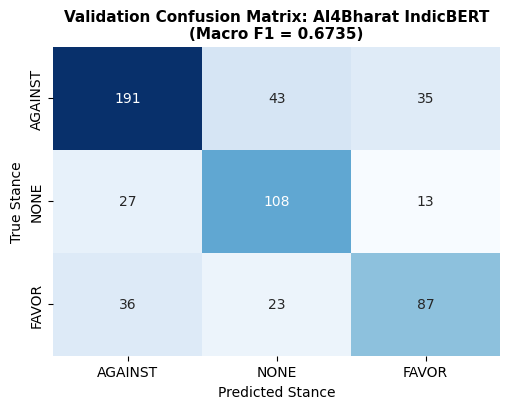

In [15]:
# ============================================================================
# CELL 5: Fine-Tune Model 1 — AI4Bharat IndicBERT (Full Dataset)
# ============================================================================
train_and_evaluate_model(
    model_key="indicbert",
    display_name="AI4Bharat IndicBERT",
    checkpoint_candidates=[
        "ai4bharat/IndicBERTv2-MLM-only",
        "ai4bharat/indic-bert",
    ],
)

STARTING FINE-TUNING ON FULL DATASET (2,251 Train / 563 Val): Google MuRIL
Loading checkpoint: 'google/muril-base-cased' ...


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

... (12 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,F1 Against,F1 None,F1 Favor
1.103539,1.100793,4,0.490231,0.470789,0.412965,0.353892,0.418042,0.653061,0.013333,0.395280


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


----------------------------------------------------------------------
VALIDATION RESULTS FOR: Google MuRIL (google/muril-base-cased)
----------------------------------------------------------------------
Saved HF Checkpoint  : /kaggle/working/saved_models/muril
Training Time        : 108.27 seconds
Validation Accuracy  : 0.4902
Validation Macro F1  : 0.3539  <-- Primary Metric
Validation Weight F1 : 0.4180

Detailed Per-Class Report (Validation Set, n = 563):
              precision    recall  f1-score   support

     AGAINST     0.5652    0.7732    0.6531       269
        NONE     0.5000    0.0068    0.0133       148
       FAVOR     0.3472    0.4589    0.3953       146

    accuracy                         0.4902       563
   macro avg     0.4708    0.4130    0.3539       563
weighted avg     0.4915    0.4902    0.4180       563



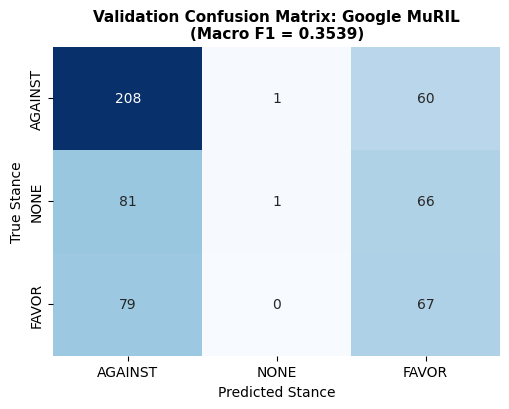

In [16]:
# ============================================================================
# CELL 6: Fine-Tune Model 2 — Google MuRIL (Full Dataset)
# ============================================================================
train_and_evaluate_model(
    model_key="muril",
    display_name="Google MuRIL",
    checkpoint_candidates=[
        "google/muril-base-cased",
    ],
)

STARTING FINE-TUNING ON FULL DATASET (2,251 Train / 563 Val): XLM-RoBERTa
Loading checkpoint: 'xlm-roberta-base' ...


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

... (14 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,F1 Against,F1 None,F1 Favor
0.666491,0.914602,8,0.696270,0.676246,0.678253,0.676739,0.696398,0.767790,0.611111,0.651316


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


----------------------------------------------------------------------
VALIDATION RESULTS FOR: XLM-RoBERTa (xlm-roberta-base)
----------------------------------------------------------------------
Saved HF Checkpoint  : /kaggle/working/saved_models/xlmr
Training Time        : 229.59 seconds
Validation Accuracy  : 0.6963
Validation Macro F1  : 0.6767  <-- Primary Metric
Validation Weight F1 : 0.6964

Detailed Per-Class Report (Validation Set, n = 563):
              precision    recall  f1-score   support

     AGAINST     0.7736    0.7621    0.7678       269
        NONE     0.6286    0.5946    0.6111       148
       FAVOR     0.6266    0.6781    0.6513       146

    accuracy                         0.6963       563
   macro avg     0.6762    0.6783    0.6767       563
weighted avg     0.6973    0.6963    0.6964       563



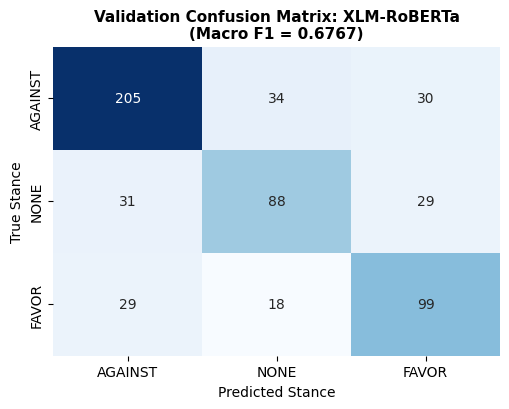

In [17]:
# ============================================================================
# CELL 7: Fine-Tune Model 3 — XLM-RoBERTa (Full Dataset)
# ============================================================================
train_and_evaluate_model(
    model_key="xlmr",
    display_name="XLM-RoBERTa",
    checkpoint_candidates=[
        "xlm-roberta-base",
        "FacebookAI/xlm-roberta-base",
    ],
)

STARTING FINE-TUNING ON FULL DATASET (2,251 Train / 563 Val): Multilingual BERT (mBERT)
Loading checkpoint: 'bert-base-multilingual-cased' ...


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

... (14 outputs left out)

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,F1 Against,F1 None,F1 Favor
0.370646,0.920376,7,0.687389,0.668981,0.677951,0.672458,0.689755,0.751938,0.653595,0.611842


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


----------------------------------------------------------------------
VALIDATION RESULTS FOR: Multilingual BERT (mBERT) (bert-base-multilingual-cased)
----------------------------------------------------------------------
Saved HF Checkpoint  : /kaggle/working/saved_models/mbert
Training Time        : 177.65 seconds
Validation Accuracy  : 0.6874
Validation Macro F1  : 0.6725  <-- Primary Metric
Validation Weight F1 : 0.6898

Detailed Per-Class Report (Validation Set, n = 563):
              precision    recall  f1-score   support

     AGAINST     0.7854    0.7212    0.7519       269
        NONE     0.6329    0.6757    0.6536       148
       FAVOR     0.5886    0.6370    0.6118       146

    accuracy                         0.6874       563
   macro avg     0.6690    0.6780    0.6725       563
weighted avg     0.6943    0.6874    0.6898       563



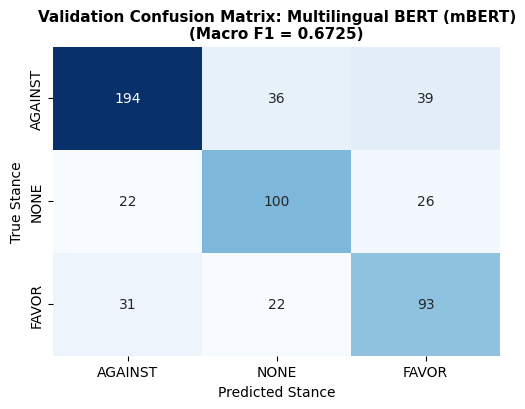

In [18]:
# ============================================================================
# CELL 8: Fine-Tune Model 4 — Multilingual BERT (mBERT) (Full Dataset)
# ============================================================================
train_and_evaluate_model(
    model_key="mbert",
    display_name="Multilingual BERT (mBERT)",
    checkpoint_candidates=[
        "bert-base-multilingual-cased",
        "google-bert/bert-base-multilingual-cased",
    ],
)

MASTER EXPERIMENTAL COMPARISON TABLE (FULL DATASET, VALIDATION n = 563)
                  Model Name           Pretrained Checkpoint  Accuracy  Macro F1  Weighted F1  F1 (AGAINST)  F1 (NONE)  F1 (FAVOR)  Training Time (s)
1                XLM-RoBERTa                xlm-roberta-base    0.6963    0.6767       0.6964        0.7678     0.6111      0.6513             229.59
2        AI4Bharat IndicBERT  ai4bharat/IndicBERTv2-MLM-only    0.6856    0.6735       0.6859        0.7304     0.6708      0.6192             197.02
3  Multilingual BERT (mBERT)    bert-base-multilingual-cased    0.6874    0.6725       0.6898        0.7519     0.6536      0.6118             177.65
4               Google MuRIL         google/muril-base-cased    0.4902    0.3539       0.4180        0.6531     0.0133      0.3953             108.27

>>> BEST VALIDATION MODEL ON FULL DATASET: XLM-RoBERTa (Macro F1 = 0.6767) <<<


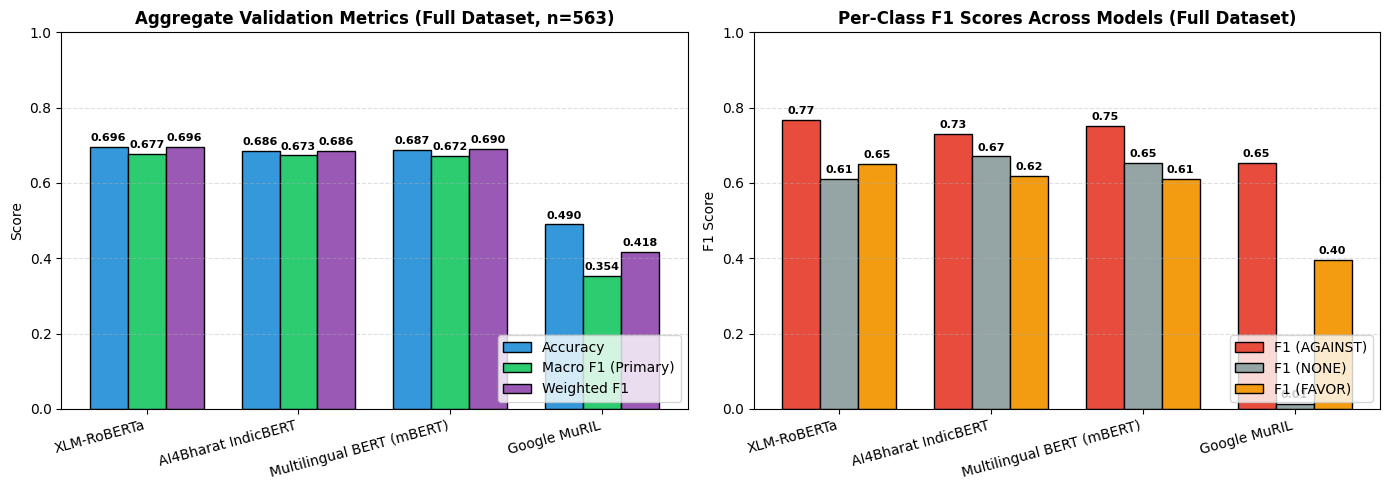

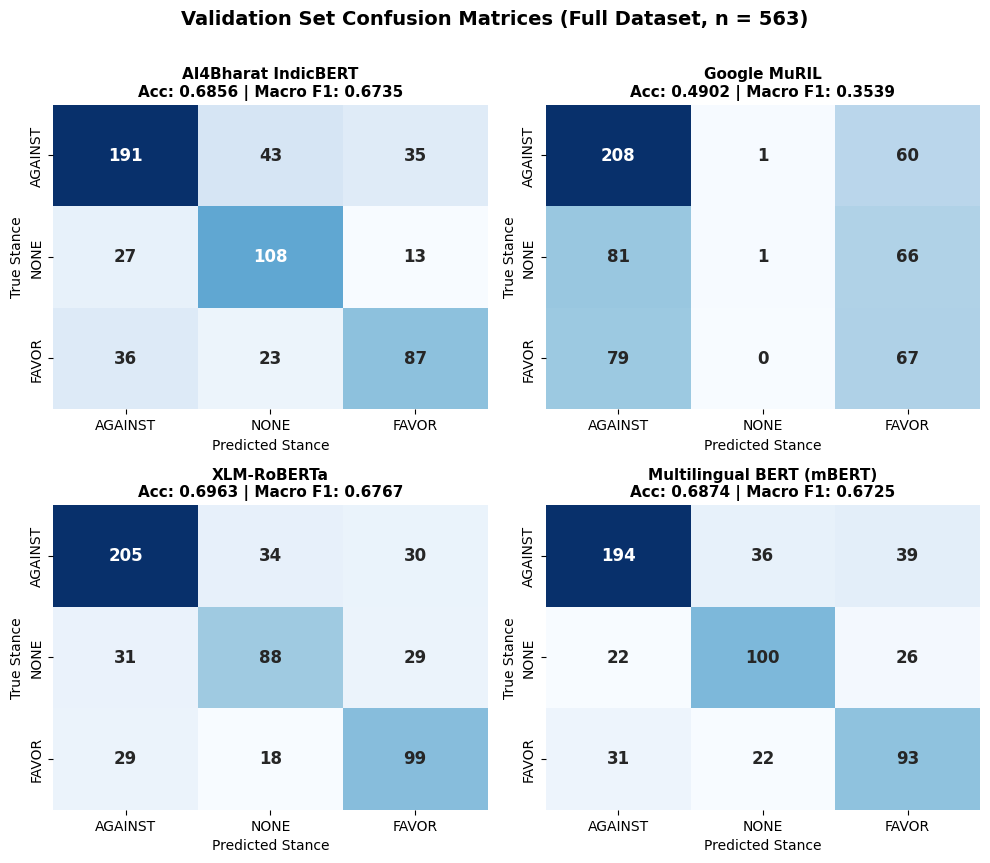

In [19]:
# ============================================================================
# CELL 9: Master Experimental Comparison Table & Charts (Full Dataset)
# ============================================================================
config_str = (
    f"lr={HYPERPARAMS['learning_rate']}, bs={HYPERPARAMS['batch_size']}, "
    f"max_len={HYPERPARAMS['max_length']}, epochs={HYPERPARAMS['num_epochs']} (ES=2), Weighted CE"
)

comparison_rows = []
for key in ["indicbert", "muril", "xlmr", "mbert"]:
    res = MODEL_RESULTS[key]
    comparison_rows.append({
        "Model Name": res["Model Name"],
        "Pretrained Checkpoint": res["Pretrained Checkpoint"],
        "Training Configuration": config_str,
        "Accuracy": res["Accuracy"],
        "Macro F1": res["Macro F1"],
        "Weighted F1": res["Weighted F1"],
        "F1 (AGAINST)": res["F1 (AGAINST)"],
        "F1 (NONE)": res["F1 (NONE)"],
        "F1 (FAVOR)": res["F1 (FAVOR)"],
        "Training Time (s)": res["Training Time (s)"],
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)
comparison_df.index = comparison_df.index + 1

comparison_csv_path = "/kaggle/working/validation_model_comparison_full.csv"
comparison_df.to_csv(comparison_csv_path, index_label="Rank")

print("=" * 95)
print("MASTER EXPERIMENTAL COMPARISON TABLE (FULL DATASET, VALIDATION n = 563)")
print("=" * 95)
display_cols = [
    "Model Name", "Pretrained Checkpoint", "Accuracy", "Macro F1",
    "Weighted F1", "F1 (AGAINST)", "F1 (NONE)", "F1 (FAVOR)", "Training Time (s)"
]
print(comparison_df[display_cols].to_string())

best_val_model_name = comparison_df.iloc[0]["Model Name"]
best_val_macro_f1 = comparison_df.iloc[0]["Macro F1"]
print(f"\n>>> BEST VALIDATION MODEL ON FULL DATASET: {best_val_model_name} (Macro F1 = {best_val_macro_f1:.4f}) <<<")

# Plot Aggregate & Per-Class Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(comparison_df))
width = 0.25

bars1 = axes[0].bar(x - width, comparison_df["Accuracy"], width, label="Accuracy", color="#3498db", edgecolor="black")
bars2 = axes[0].bar(x, comparison_df["Macro F1"], width, label="Macro F1 (Primary)", color="#2ecc71", edgecolor="black")
bars3 = axes[0].bar(x + width, comparison_df["Weighted F1"], width, label="Weighted F1", color="#9b59b6", edgecolor="black")

axes[0].set_title("Aggregate Validation Metrics (Full Dataset, n=563)", fontsize=12, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison_df["Model Name"], rotation=15, ha="right")
axes[0].set_ylim(0.0, 1.0)
axes[0].set_ylabel("Score")
axes[0].legend(loc="lower right")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

for bar_group in [bars1, bars2, bars3]:
    for bar in bar_group:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width() / 2.0, h + 0.01, f"{h:.3f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

b_ag = axes[1].bar(x - width, comparison_df["F1 (AGAINST)"], width, label="F1 (AGAINST)", color="#e74c3c", edgecolor="black")
b_no = axes[1].bar(x, comparison_df["F1 (NONE)"], width, label="F1 (NONE)", color="#95a5a6", edgecolor="black")
b_fa = axes[1].bar(x + width, comparison_df["F1 (FAVOR)"], width, label="F1 (FAVOR)", color="#f39c12", edgecolor="black")

axes[1].set_title("Per-Class F1 Scores Across Models (Full Dataset)", fontsize=12, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparison_df["Model Name"], rotation=15, ha="right")
axes[1].set_ylim(0.0, 1.0)
axes[1].set_ylabel("F1 Score")
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

for bar_group in [b_ag, b_no, b_fa]:
    for bar in bar_group:
        h = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width() / 2.0, h + 0.01, f"{h:.2f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.savefig("/kaggle/working/model_comparison_metrics_full.png", dpi=300)
plt.show()

# Plot 2x2 Grid of All 4 Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
axes = axes.flatten()

for idx, key in enumerate(["indicbert", "muril", "xlmr", "mbert"]):
    res = MODEL_RESULTS[key]
    sns.heatmap(
        res["Confusion Matrix"],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        cbar=False,
        ax=axes[idx],
        annot_kws={"size": 12, "weight": "bold"},
    )
    axes[idx].set_title(
        f"{res['Model Name']}\nAcc: {res['Accuracy']:.4f} | Macro F1: {res['Macro F1']:.4f}",
        fontsize=11,
        fontweight="bold",
    )
    axes[idx].set_xlabel("Predicted Stance")
    axes[idx].set_ylabel("True Stance")

plt.suptitle("Validation Set Confusion Matrices (Full Dataset, n = 563)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("/kaggle/working/all_4_confusion_matrices_full.png", dpi=300)
plt.show()

RUNNING ALL 4 FINE-TUNED MODELS ON 103 SCRAPED HINDI COMMENTS


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  [DONE] AI4Bharat IndicBERT        -> Mean Conf: 0.6757 | Counts: {'NONE': np.int64(51), 'FAVOR': np.int64(30), 'AGAINST': np.int64(22)}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  [DONE] Google MuRIL               -> Mean Conf: 0.3358 | Counts: {'FAVOR': np.int64(63), 'AGAINST': np.int64(40)}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  [DONE] XLM-RoBERTa                -> Mean Conf: 0.8201 | Counts: {'NONE': np.int64(64), 'FAVOR': np.int64(31), 'AGAINST': np.int64(8)}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  [DONE] Multilingual BERT (mBERT)  -> Mean Conf: 0.7964 | Counts: {'NONE': np.int64(77), 'FAVOR': np.int64(18), 'AGAINST': np.int64(8)}

PREDICTED STANCE DISTRIBUTION ACROSS ALL 4 MODELS (HINDI YOUTUBE COMMENTS)
                           FAVOR  NONE  AGAINST  Mean Confidence
AI4Bharat IndicBERT         30.0  51.0     22.0           0.6757
Google MuRIL                63.0   0.0     40.0           0.3358
XLM-RoBERTa                 31.0  64.0      8.0           0.8201
Multilingual BERT (mBERT)   18.0  77.0      8.0           0.7964


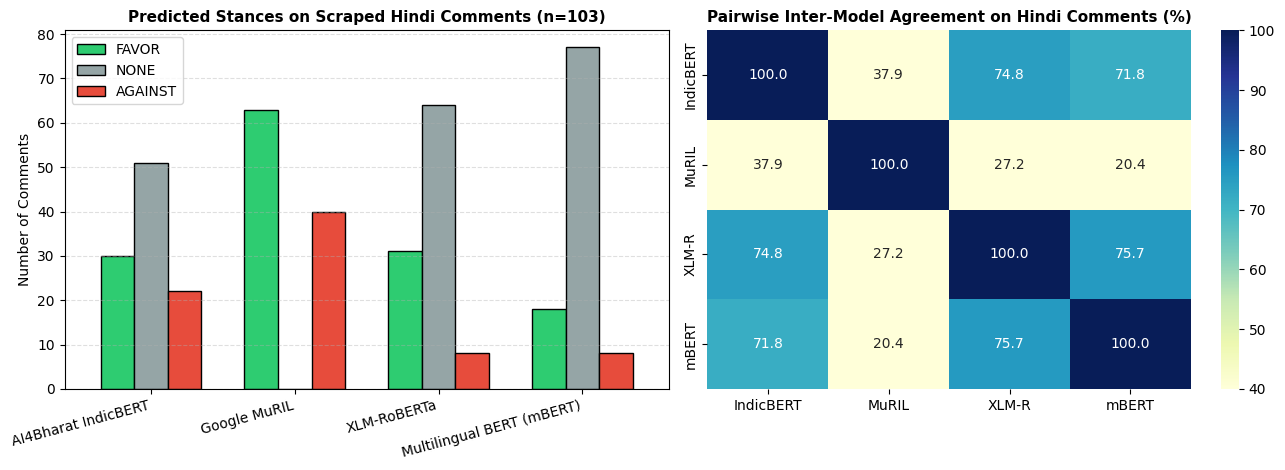


Saved Official Submission CSV to: /kaggle/working/submission_predictions.csv


In [20]:
# ============================================================================
# CELL 10: Run All 4 Fine-Tuned Models on Scraped Hindi YouTube Comments
# ============================================================================
import os
import re
import html
import torch
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

LABEL2ID = {"AGAINST": 0, "NONE": 1, "FAVOR": 2}
ID2LABEL = {0: "AGAINST", 1: "NONE", 2: "FAVOR"}
CLASS_NAMES = ["AGAINST", "NONE", "FAVOR"]

MODEL_KEYS_ORDER = [
    ("indicbert", "AI4Bharat IndicBERT"),
    ("muril", "Google MuRIL"),
    ("xlmr", "XLM-RoBERTa"),
    ("mbert", "Multilingual BERT (mBERT)"),
]

def clean_social_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = html.unescape(text)
    text = re.sub(r"#SemST\b", "", text, flags=re.IGNORECASE)
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"\bRT\s+@\w+:?", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def predict_hindi_stance(checkpoint_dir: str, texts: list, batch_size: int = 32):
    tokenizer = AutoTokenizer.from_pretrained(checkpoint_dir)
    model = AutoModelForSequenceClassification.from_pretrained(checkpoint_dir)
    model.to(device)
    model.eval()

    all_preds, all_confs = [], []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i : i + batch_size]
            encoded = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt",
            ).to(device)
            outputs = model(**encoded)
            probs = torch.softmax(outputs.logits, dim=-1).cpu().numpy()
            pred_ids = np.argmax(probs, axis=-1)
            confidences = np.max(probs, axis=-1)
            all_preds.extend([ID2LABEL[int(pid)] for pid in pred_ids])
            all_confs.extend([round(float(c), 4) for c in confidences])

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return all_preds, all_confs

# 1. Automatically find the uploaded Hindi CSV file in /kaggle/input
hindi_test_path = None
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.lower().endswith(".csv"):
            hindi_test_path = os.path.join(root, f)
            break
    if hindi_test_path:
        break

if hindi_test_path is None:
    raise FileNotFoundError(
        "Could not find 'hindi_youtube_test_data.csv' in /kaggle/input! "
        "Please upload it via '+ Add Input' in the right sidebar."
    )

hindi_test_df = pd.read_csv(hindi_test_path, encoding="utf-8-sig")
if "ID" not in hindi_test_df.columns:
    hindi_test_df.insert(0, "ID", range(1, len(hindi_test_df) + 1))

text_col = None
for candidate in ["Clean_Comment", "Raw_Comment", "Comment", "Tweet", "text", "comment"]:
    if candidate in hindi_test_df.columns:
        text_col = candidate
        break
if text_col is None:
    text_col = hindi_test_df.select_dtypes(include="object").columns[-1]

hindi_test_df["hindi_clean_text"] = hindi_test_df[text_col].astype(str).apply(clean_social_text)

print("=" * 80)
print(f"RUNNING ALL 4 FINE-TUNED MODELS ON {len(hindi_test_df)} SCRAPED HINDI COMMENTS")
print("=" * 80)

hindi_results_df = pd.DataFrame({
    "ID": hindi_test_df["ID"],
    "Hindi_Comment": hindi_test_df["hindi_clean_text"],
})

dist_summary = {}
for m_key, m_name in MODEL_KEYS_ORDER:
    ckpt_dir = f"/kaggle/working/saved_models/{m_key}"
    preds, confs = predict_hindi_stance(ckpt_dir, hindi_results_df["Hindi_Comment"].tolist())
    hindi_results_df[f"{m_key}_pred"] = preds
    hindi_results_df[f"{m_key}_conf"] = confs

    counts = pd.Series(preds).value_counts()
    dist_summary[m_name] = {
        "FAVOR": int(counts.get("FAVOR", 0)),
        "NONE": int(counts.get("NONE", 0)),
        "AGAINST": int(counts.get("AGAINST", 0)),
        "Mean Confidence": round(float(np.mean(confs)), 4),
    }
    print(f"  [DONE] {m_name:26s} -> Mean Conf: {np.mean(confs):.4f} | Counts: {dict(counts)}")

# 2. Compute Majority Vote & Agreement Across the 4 Models
pred_cols = [f"{k}_pred" for k, _ in MODEL_KEYS_ORDER]
def get_majority_and_agreement(row):
    votes = [row[c] for c in pred_cols]
    most_common_label, num_agree = Counter(votes).most_common(1)[0]
    if num_agree == 2 and len(set(votes)) == 2:
        most_common_label = row["indicbert_pred"]
    return pd.Series([most_common_label, num_agree])

hindi_results_df[["Majority_Vote_Stance", "Models_Agreeing_Count"]] = (
    hindi_results_df.apply(get_majority_and_agreement, axis=1)
)

print("\n" + "=" * 80)
print("PREDICTED STANCE DISTRIBUTION ACROSS ALL 4 MODELS (HINDI YOUTUBE COMMENTS)")
print("=" * 80)
dist_df = pd.DataFrame(dist_summary).T
print(dist_df.to_string())

# 3. Plot Prediction Distribution & Pairwise Agreement Heatmap
agree_matrix = np.zeros((4, 4))
short_names = ["IndicBERT", "MuRIL", "XLM-R", "mBERT"]
for i, (k1, _) in enumerate(MODEL_KEYS_ORDER):
    for j, (k2, _) in enumerate(MODEL_KEYS_ORDER):
        agree_matrix[i, j] = (hindi_results_df[f"{k1}_pred"] == hindi_results_df[f"{k2}_pred"]).mean() * 100
agree_df = pd.DataFrame(agree_matrix.round(2), index=short_names, columns=short_names)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
dist_df[["FAVOR", "NONE", "AGAINST"]].plot(
    kind="bar", ax=axes[0], color=["#2ecc71", "#95a5a6", "#e74c3c"], edgecolor="black", width=0.7
)
axes[0].set_title(f"Predicted Stances on Scraped Hindi Comments (n={len(hindi_results_df)})", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Number of Comments")
axes[0].set_xticklabels(dist_df.index, rotation=15, ha="right")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

sns.heatmap(agree_df, annot=True, fmt=".1f", cmap="YlGnBu", vmin=40, vmax=100, ax=axes[1])
axes[1].set_title("Pairwise Inter-Model Agreement on Hindi Comments (%)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/hindi_test_model_comparison.png", dpi=300)
plt.show()

# 4. Save Prediction CSVs
hindi_results_df.to_csv("/kaggle/working/all_4_models_hindi_predictions.csv", index=False, encoding="utf-8-sig")
submission_df = pd.DataFrame({
    "ID": hindi_results_df["ID"],
    "Predicted Label": hindi_results_df["Majority_Vote_Stance"],
})
submission_df.to_csv("/kaggle/working/submission_predictions.csv", index=False, encoding="utf-8-sig")
print("\nSaved Official Submission CSV to: /kaggle/working/submission_predictions.csv")

In [21]:
# ============================================================================
# CELL 11: BULLETPROOF PROFESSOR EVALUATOR (.TXT, .CSV, .XLSX, OR TYPED TEXT)
# ============================================================================
import os
import re
import html
import torch
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

def normalize_stance_label(val: str) -> str:
    s = str(val).strip().upper()
    if s in ["FAVOR", "FAVOUR", "SUPPORT", "PRO", "2"]:
        return "FAVOR"
    elif s in ["AGAINST", "OPPOSE", "CON", "0"]:
        return "AGAINST"
    else:
        return "NONE"

def read_file_any_encoding(filepath: str, sep=None):
    """Tries utf-8-sig, utf-8, and cp1252 so no file ever fails with encoding errors."""
    for enc in ["utf-8-sig", "utf-8", "cp1252", "latin1"]:
        try:
            if sep is not None:
                return pd.read_csv(filepath, sep=sep, encoding=enc)
            else:
                return pd.read_csv(filepath, encoding=enc)
        except Exception:
            continue
    raise ValueError(f"Could not read file: {filepath}")

def smart_load_professor_input(test_input):
    """
    Automatically handles:
      1. Plain .txt file (one sentence per line) OR Tab-separated .txt/.tsv file
      2. .csv file (with or without headers)
      3. .xlsx / .xls Excel file
      4. Single sentence string, multi-line string, or Python list of sentences
    """
    # Check if test_input is a filename or path
    if isinstance(test_input, str) and test_input.strip().lower().endswith((".txt", ".tsv", ".csv", ".xlsx", ".xls")):
        filepath = test_input.strip()
        # If only filename was given (e.g. "test.txt"), search /kaggle/input and /kaggle/working automatically
        if not os.path.exists(filepath):
            for search_dir in ["/kaggle/input", "/kaggle/working"]:
                for root, _, files in os.walk(search_dir):
                    for f in files:
                        if f.lower() == os.path.basename(filepath).lower():
                            filepath = os.path.join(root, f)
                            break

        if not os.path.exists(filepath):
            raise FileNotFoundError(f"Could not find file '{test_input}' in /kaggle/input or /kaggle/working!")

        print(f"[STEP 1] Loading Professor's File: {filepath}")
        ext = filepath.lower()

        if ext.endswith((".xlsx", ".xls")):
            df = pd.read_excel(filepath)

        elif ext.endswith((".txt", ".tsv")):
            # Inspect the first line of the .txt file to see if it is tab-separated or plain text lines
            raw_lines = []
            for enc in ["utf-8-sig", "utf-8", "cp1252", "latin1"]:
                try:
                    with open(filepath, "r", encoding=enc) as f:
                        raw_lines = [line.strip() for line in f.readlines() if line.strip()]
                    break
                except Exception:
                    continue

            if len(raw_lines) > 0 and "\t" in raw_lines[0]:
                # Tab-separated .txt file (like SemEval format)
                df = read_file_any_encoding(filepath, sep="\t")
            else:
                # Plain .txt file with one sentence per line!
                df = pd.DataFrame({"ID": range(1, len(raw_lines) + 1), "Comment": raw_lines})

        else:
            # .csv file
            df = read_file_any_encoding(filepath)

        return df

    # Otherwise, test_input is typed text (single sentence, multi-line string, or list of sentences)
    elif isinstance(test_input, str):
        lines = [line.strip() for line in test_input.strip().split("\n") if line.strip()]
        print(f"[STEP 1] Loading {len(lines)} Typed Hindi Sentence(s)")
        return pd.DataFrame({"ID": range(1, len(lines) + 1), "Comment": lines})

    elif isinstance(test_input, list):
        print(f"[STEP 1] Loading List of {len(test_input)} Typed Hindi Sentence(s)")
        return pd.DataFrame({"ID": range(1, len(test_input) + 1), "Comment": test_input})

    else:
        raise ValueError("Invalid TEST_INPUT format!")


def run_professor_evaluation(test_input):
    # STEP 1: Smart Load (.txt, .csv, .xlsx, or typed text)
    df_eval = smart_load_professor_input(test_input)

    if "ID" not in df_eval.columns:
        df_eval.insert(0, "ID", range(1, len(df_eval) + 1))

    # Automatically detect the text column
    t_col = None
    for c in ["Comment", "Clean_Comment", "Raw_Comment", "Tweet", "Text", "text", "comment", "sentence"]:
        if c in df_eval.columns:
            t_col = c
            break
    if t_col is None:
        str_cols = df_eval.select_dtypes(include="object").columns
        t_col = str_cols[0] if len(str_cols) > 0 else df_eval.columns[-1]

    # STEP 2: Text Cleaning & Normalization
    print("[STEP 2] Performing Text Cleaning & Normalization ...")
    df_eval["Clean_Text"] = df_eval[t_col].astype(str).apply(clean_social_text)

    # STEP 3: Run Inference Across All 4 Fine-Tuned Models
    print(f"[STEP 3] Running All 4 Fine-Tuned Models on {len(df_eval)} sample(s) ...")
    for m_key, m_name in MODEL_KEYS_ORDER:
        ckpt_dir = f"/kaggle/working/saved_models/{m_key}"
        preds, confs = predict_hindi_stance(ckpt_dir, df_eval["Clean_Text"].tolist())
        df_eval[f"{m_key}_pred"] = preds
        df_eval[f"{m_key}_conf"] = confs

    pred_cols = [f"{k}_pred" for k, _ in MODEL_KEYS_ORDER]
    df_eval["Final_Predicted_Label"] = df_eval[pred_cols].apply(
        lambda r: Counter(r.tolist()).most_common(1)[0][0], axis=1
    )

    # Print sample predictions (up to first 15 rows)
    print("\n" + "=" * 85)
    print(f"PREDICTION RESULTS (Showing {min(len(df_eval), 15)} of {len(df_eval)} total rows)")
    print("=" * 85)
    for _, r in df_eval.head(15).iterrows():
        print(f"\n[ID {r['ID']}] Raw Text   : {r[t_col]}")
        print(f"       Clean Text : {r['Clean_Text']}")
        for m_key, m_name in MODEL_KEYS_ORDER:
            print(f"  -> {m_name:26s} : {r[f'{m_key}_pred']:7s} (Confidence: {r[f'{m_key}_conf']*100:.2f}%)")
        print(f"  >>> FINAL PREDICTED STANCE    : {r['Final_Predicted_Label']} <<<")

    # STEP 4: If Ground-Truth Labels Exist -> Compute Macro F1, Accuracy, Precision, Recall & Confusion Matrix
    l_col = None
    for c in ["Stance", "True_Stance", "Label", "label", "stance", "Target_Stance"]:
        if c in df_eval.columns:
            l_col = c
            break

    if l_col is not None and df_eval[l_col].notna().all():
        print("\n" + "=" * 95)
        print(f"[STEP 4] GROUND-TRUTH LABELS DETECTED ('{l_col}') -> OFFICIAL EVALUATION METRICS")
        print("=" * 95)
        true_ids = df_eval[l_col].apply(normalize_stance_label).map(LABEL2ID).values

        metrics_rows = []
        cms = {}
        for m_key, m_name in MODEL_KEYS_ORDER:
            pred_ids = df_eval[f"{m_key}_pred"].map(LABEL2ID).values
            acc = accuracy_score(true_ids, pred_ids)
            mp, mr, mf1, _ = precision_recall_fscore_support(true_ids, pred_ids, average="macro", zero_division=0)
            wf1 = f1_score(true_ids, pred_ids, average="weighted", zero_division=0)
            _, _, per_f1, _ = precision_recall_fscore_support(true_ids, pred_ids, average=None, labels=[0, 1, 2], zero_division=0)
            cms[m_key] = confusion_matrix(true_ids, pred_ids, labels=[0, 1, 2])

            metrics_rows.append({
                "Model Name": m_name,
                "Macro F1-Score (Primary)": round(float(mf1), 4),
                "Accuracy": round(float(acc), 4),
                "Macro Precision": round(float(mp), 4),
                "Macro Recall": round(float(mr), 4),
                "Weighted F1": round(float(wf1), 4),
                "F1 (AGAINST)": round(float(per_f1[0]), 4),
                "F1 (NONE)": round(float(per_f1[1]), 4),
                "F1 (FAVOR)": round(float(per_f1[2]), 4),
            })

        metrics_df = pd.DataFrame(metrics_rows).sort_values(by="Macro F1-Score (Primary)", ascending=False).reset_index(drop=True)
        metrics_df.index = metrics_df.index + 1
        print(metrics_df.to_string())

        fig, axes = plt.subplots(2, 2, figsize=(10, 8))
        axes = axes.flatten()
        for idx, (m_key, m_name) in enumerate(MODEL_KEYS_ORDER):
            sns.heatmap(
                cms[m_key], annot=True, fmt="d", cmap="Greens",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[idx]
            )
            axes[idx].set_title(f"{m_name}", fontsize=11, fontweight="bold")
            axes[idx].set_xlabel("Predicted Stance")
            axes[idx].set_ylabel("True Stance")
        plt.suptitle("Professor's Test Set Confusion Matrices", fontsize=13, fontweight="bold", y=1.01)
        plt.tight_layout()
        plt.show()

    # STEP 5: Save Final Predictions CSVs (id,label AND ID,Predicted Label)
    out_dir = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
    sub_out = pd.DataFrame({
        "ID": df_eval["ID"],
        "Predicted Label": df_eval["Final_Predicted_Label"],
    })
    out_csv_path = os.path.join(out_dir, "professor_test_predictions.csv")
    sub_out.to_csv(out_csv_path, index=False, encoding="utf-8-sig")

    diagram_out = pd.DataFrame({
        "id": df_eval["ID"],
        "label": df_eval["Final_Predicted_Label"],
    })
    diagram_csv_path = os.path.join(out_dir, "output_predictions.csv")
    diagram_out.to_csv(diagram_csv_path, index=False, encoding="utf-8-sig")
    print(f"\n[STEP 5] Saved Output CSV (id, label) to            : {diagram_csv_path}")
    print(f"[STEP 5] Saved Predictions CSV (ID, Predicted Label): {out_csv_path}")
    return df_eval


# ============================================================================
# PUT WHATEVER YOUR PROFESSOR GIVES YOU INSIDE 'TEST_INPUT' BELOW:
#   1. If Professor gives a .txt file  -> TEST_INPUT = "test.txt" (or full path)
#   2. If Professor gives a .csv file  -> TEST_INPUT = "test.csv" (or full path)
#   3. If Professor gives typed text   -> TEST_INPUT = "ग्लोबल वार्मिंग..."
#   4. If Professor gives multiple lines ->
#      TEST_INPUT = """
#      ग्लोबल वार्मिंग आज पूरी दुनिया के लिए एक बहुत गंभीर संकट है।
#      क्लाइमेट चेंज सब झूठ और बकवास है।
#      आज का क्रिकेट मैच बहुत अच्छा था।
#      """
# ============================================================================
TEST_INPUT = """
ग्लोबल वार्मिंग आज पूरी दुनिया के लिए एक बहुत गंभीर संकट बन चुका है।
क्लाइमेट चेंज सब झूठ और बकवास है, ऐसा कुछ नहीं होता।
आज भारत का क्रिकेट मैच बहुत शानदार था।
"""

_ = run_professor_evaluation(TEST_INPUT)

[STEP 1] Loading 3 Typed Hindi Sentence(s)
[STEP 2] Performing Text Cleaning & Normalization ...
[STEP 3] Running All 4 Fine-Tuned Models on 3 sample(s) ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


PREDICTION RESULTS (Showing 3 of 3 total rows)

[ID 1] Raw Text   : ग्लोबल वार्मिंग आज पूरी दुनिया के लिए एक बहुत गंभीर संकट बन चुका है।
       Clean Text : ग्लोबल वार्मिंग आज पूरी दुनिया के लिए एक बहुत गंभीर संकट बन चुका है।
  -> AI4Bharat IndicBERT        : FAVOR   (Confidence: 97.84%)
  -> Google MuRIL               : FAVOR   (Confidence: 33.91%)
  -> XLM-RoBERTa                : FAVOR   (Confidence: 96.86%)
  -> Multilingual BERT (mBERT)  : NONE    (Confidence: 71.74%)
  >>> FINAL PREDICTED STANCE    : FAVOR <<<

[ID 2] Raw Text   : क्लाइमेट चेंज सब झूठ और बकवास है, ऐसा कुछ नहीं होता।
       Clean Text : क्लाइमेट चेंज सब झूठ और बकवास है, ऐसा कुछ नहीं होता।
  -> AI4Bharat IndicBERT        : FAVOR   (Confidence: 97.57%)
  -> Google MuRIL               : FAVOR   (Confidence: 33.82%)
  -> XLM-RoBERTa                : NONE    (Confidence: 83.73%)
  -> Multilingual BERT (mBERT)  : NONE    (Confidence: 73.57%)
  >>> FINAL PREDICTED STANCE    : FAVOR <<<

[ID 3] Raw Text   : आज भारत का क्